# Random Forest Classification

## ⬇️ Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.ensemble import RandomForestClassifier
import os

from tfidf_preprocessing import TFIDFPreprocessing

[nltk_data] Downloading package stopwords to /home/epita/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/epita/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 🛠️ With TFIDFPreprocessing

In [2]:
preprocessor = TFIDFPreprocessing()
data = preprocessor.load('../../data/RAW_recipes.csv')
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)
preprocessor.fit(train_data)
X_train, y_train = preprocessor.transform(train_data)
X_test, y_test = preprocessor.transform(test_data)

Loading dataset...
Starting fit process...
Cleaning Recipe name...
Cleaning description, tags, steps, ingredients...
Map tag to cuisine to build target...
Determine valid cuisines based on minimum sample count
Identified 53 valid cuisines with at least 50 samples each.
Filter data to only include valid cuisines
Extract primary cuisine
Fitting TF-IDF vectorizers...
Fitting label encoder...
Starting transform process...
Cleaning Recipe name...
Cleaning description, tags, steps, ingredients...
Map tag to cuisine to build target...
Applying TF-IDF transformations...
Building feature matrix...
Starting transform process...
Cleaning Recipe name...
Cleaning description, tags, steps, ingredients...
Map tag to cuisine to build target...
Applying TF-IDF transformations...
Building feature matrix...


AttributeError: 'TFIDFPreprocessing' object has no attribute 'save'

## Model

### Training

In [3]:
print("\nTraining Random Forest Classifier...")

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)


Training Random Forest Classifier...
Accuracy: 0.6388


### Evaluation

In [4]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='micro')

print(f"\nMicro-average precision: {precision:.4f}")
print(f"Micro-average recall: {recall:.4f}")
print(f"Micro-average F1-score: {f1:.4f}")

Accuracy: 0.6388

Micro-average precision: 0.6388
Micro-average recall: 0.6388
Micro-average F1-score: 0.6388


In [6]:
print(classification_report(y_test, y_pred, target_names=preprocessor.label_encoder.classes_))

                               precision    recall  f1-score   support

               Asia – General       0.56      0.71      0.63      1378
                 Asia – South       0.00      0.00      0.00        26
             Asia – Southeast       0.75      0.02      0.03       178
  Central America & Caribbean       0.00      0.00      0.00        28
                      Chinese       0.63      0.21      0.31       380
             Europe – Eastern       1.00      0.03      0.06       170
             Europe – General       0.62      0.21      0.31      1221
            Europe – Northern       0.75      0.02      0.03       196
             Europe – Western       0.67      0.09      0.16      1071
                       French       0.92      0.16      0.27       609
                        Greek       0.00      0.00      0.00        52
                       Indian       0.00      0.00      0.00        91
                      Italian       0.70      0.58      0.64      1577
     

/nix/store/98ilsvc8x66w02jqzpn1ww9g7rr5lywq-python3-3.11.8-env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/nix/store/98ilsvc8x66w02jqzpn1ww9g7rr5lywq-python3-3.11.8-env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/nix/store/98ilsvc8x66w02jqzpn1ww9g7rr5lywq-python3-3.11.8-env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division`

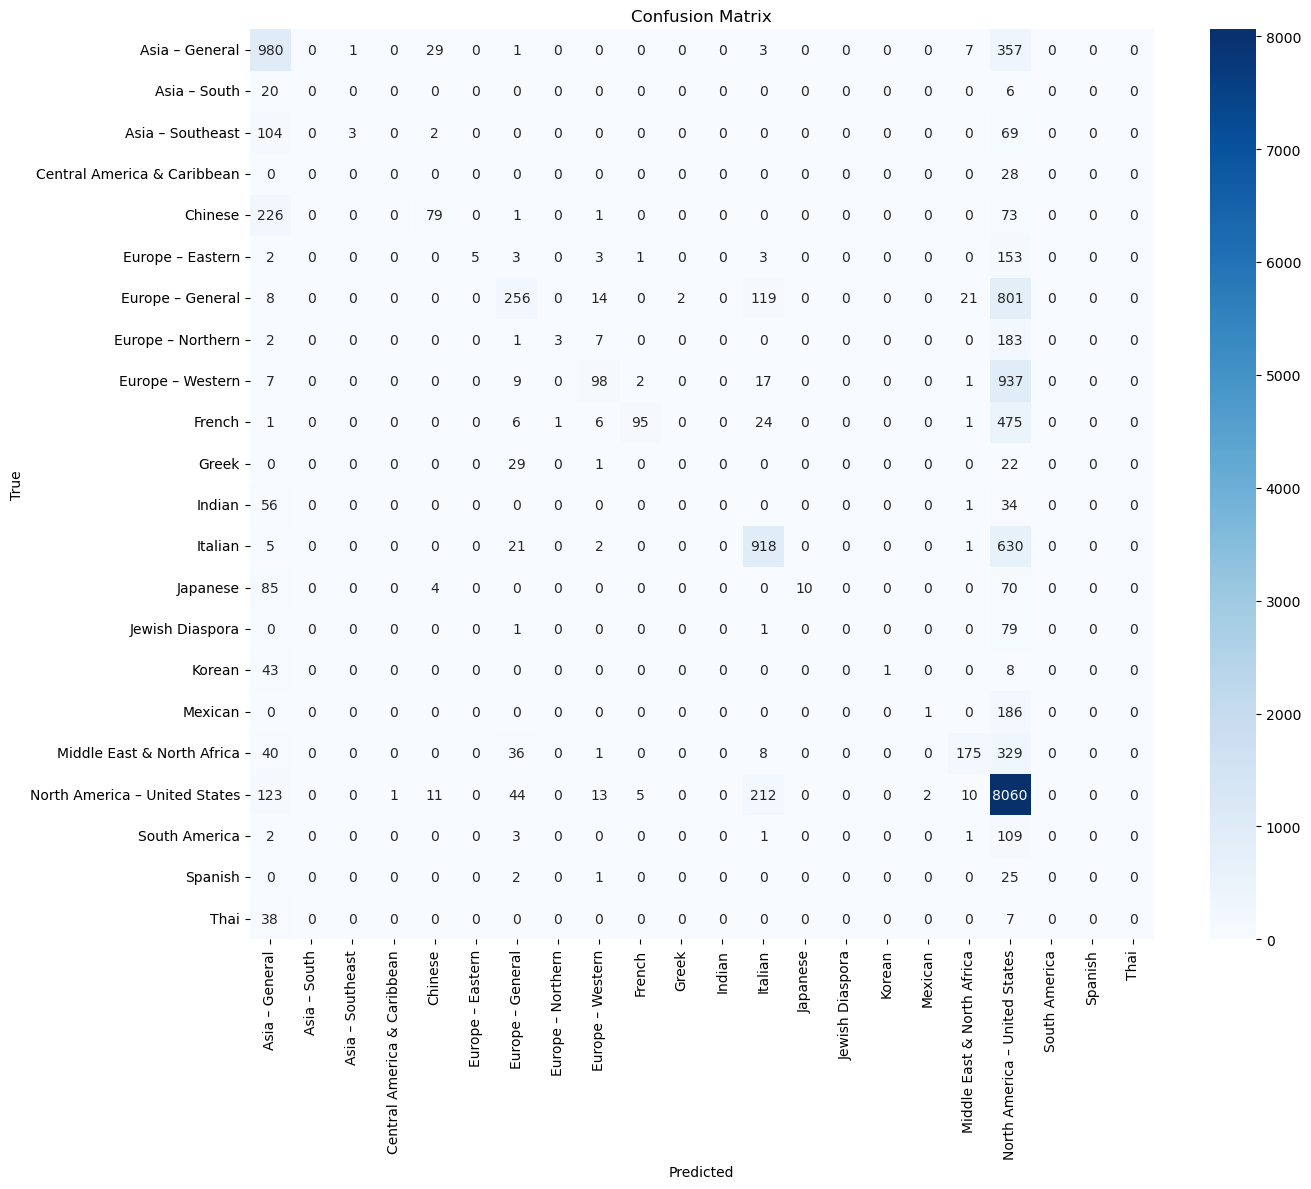

In [10]:
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=preprocessor.label_encoder.classes_, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [15]:
def predict_cuisine(model, steps_vec, ingredients_vec, recipe_steps, recipe_ingredients, n_steps, n_ingredients, label_encoder, top_n=3):
    """
    Predict top N cuisine types for a new recipe with probabilities
    
    Parameters:
    -----------
    model: trained classifier model
    steps_vec: fitted TF-IDF vectorizer for steps
    ingredients_vec: fitted TF-IDF vectorizer for ingredients
    recipe_steps: list of recipe steps
    recipe_ingredients: list of recipe ingredients
    n_steps: number of steps
    n_ingredients: number of ingredients
    label_encoder: fitted label encoder
    top_n: number of top predictions to return (default: 3)
    
    Returns:
    --------
    list of tuples (cuisine, probability) for top N predictions
    """
    # Prepare steps and ingredients text
    steps_text = ' '.join(recipe_steps)
    ingredients_text = ' '.join(recipe_ingredients)
    
    # Transform text data
    steps_features = steps_vec.transform([steps_text]).toarray()
    ingredients_features = ingredients_vec.transform([ingredients_text]).toarray()
    
    # Create token statistics
    tokens = [token for token in steps_text.split()]
    #token_count = len(tokens)
    #avg_token_length = np.mean([len(token) for token in tokens]) if tokens else 0
    
    # Combine all features
    numerical_features = np.array([[n_steps, n_ingredients]])
    X_new = np.hstack([steps_features, ingredients_features, numerical_features])
    
    # Get probability predictions for all classes
    proba = model.predict_proba(X_new)[0]
    
    # Get indices of top N predictions in descending order of probability
    top_indices = proba.argsort()[-top_n:][::-1]
    
    # Map indices to cuisine names and create (cuisine, probability) tuples
    top_predictions = []
    for idx in top_indices:
        cuisine = label_encoder.inverse_transform([idx])[0]
        probability = proba[idx]
        top_predictions.append((cuisine, probability))
    
    return top_predictions

# Test with sample recipes
print("\n===== Testing with sample recipes =====")

# Sample recipe 1
sample_recipe = data.iloc[30]
top_predictions = predict_cuisine(
    model, steps_vectorizer, ingredients_vectorizer,
    sample_recipe['steps'], sample_recipe['ingredients'],
    sample_recipe['n_steps'], sample_recipe['n_ingredients'],
    label_encoder
)

print(f"\nSample Recipe #1: {sample_recipe['name']}")
print(f"Actual cuisine: {' '.join(sample_recipe['cuisines'])}")
print("Top 3 predicted cuisines:")
for i, (cuisine, prob) in enumerate(top_predictions, 1):
    print(f"  {i}. {cuisine} (probability: {prob:.4f})")

# Sample recipe 2
sample_recipe = data.iloc[20]
top_predictions = predict_cuisine(
    model, steps_vectorizer, ingredients_vectorizer,
    sample_recipe['steps'], sample_recipe['ingredients'],
    sample_recipe['n_steps'], sample_recipe['n_ingredients'],
    label_encoder
)

print(f"\nSample Recipe #2: {sample_recipe['name']}")
print(f"Actual cuisine: {' '.join(sample_recipe['cuisines'])}")
print("Top 3 predicted cuisines:")
for i, (cuisine, prob) in enumerate(top_predictions, 1):
    print(f"  {i}. {cuisine} (probability: {prob:.4f})")

# Try one more sample
sample_recipe = data.iloc[1000]
top_predictions = predict_cuisine(
    model, steps_vectorizer, ingredients_vectorizer,
    sample_recipe['steps'], sample_recipe['ingredients'],
    sample_recipe['n_steps'], sample_recipe['n_ingredients'],
    label_encoder
)

print(f"\nSample Recipe #3: {sample_recipe['name']}")
print(f"Actual cuisine: {' '.join(sample_recipe['cuisines'])}")
print("Top 3 predicted cuisines:")
for i, (cuisine, prob) in enumerate(top_predictions, 1):
    print(f"  {i}. {cuisine} (probability: {prob:.4f})")


===== Testing with sample recipes =====

Sample Recipe #1: souper sour meatball
Actual cuisine: North America – United States North America – Canada
Top 3 predicted cuisines:
  1. North America – United States (probability: 0.4400)
  2. Europe – Western (probability: 0.1100)
  3. Asia – General (probability: 0.0700)

Sample Recipe #2: took veal prince orloff
Actual cuisine: Europe – General
Top 3 predicted cuisines:
  1. Europe – General (probability: 0.6700)
  2. North America – United States (probability: 0.2000)
  3. Europe – Western (probability: 0.0900)

Sample Recipe #3: al egg salad
Actual cuisine: North America – United States
Top 3 predicted cuisines:
  1. North America – United States (probability: 0.9300)
  2. French (probability: 0.0200)
  3. Europe – General (probability: 0.0200)
